In [1]:
import csv
import os

import matplotlib.pyplot as plt

RESULTS_DIR = "results"


def plot_sweep(filename, column):
    """Plot `column` of a sweep CSV in results/ against the error-rate scaling epsilon.

    The x-axis is logarithmic, so the epsilon = 0 (noise-free) row is left out. Two extra axes
    along the top give the matching depolarizing weights lambda_cz and lambda_sx (lambda = epsilon * rate).
    """
    with open(os.path.join(RESULTS_DIR, filename), newline="") as f:
        rows = [row for row in csv.DictReader(f) if float(row["epsilon"]) > 0]
    epsilons = [float(row["epsilon"]) for row in rows]
    values = [float(row[column]) for row in rows]

    fig, ax = plt.subplots()
    ax.plot(epsilons, values, marker="o")
    ax.set_xscale("log")
    ax.set_xlabel("epsilon")
    ax.set_ylabel(column)
    ax.set_title(filename)
    ax.grid(True, which="both", alpha=0.3)

    # lambda is linear in epsilon, so each gate's axis is the epsilon axis rescaled by its rate.
    for gate, offset in [("cz", 1.0), ("sx", 1.25)]:
        rate = float(rows[0][f"lambda_{gate}"]) / epsilons[0]
        top = ax.secondary_xaxis(offset, functions=(lambda e, r=rate: e * r, lambda l, r=rate: l / r))
        top.set_xlabel(f"lambda_{gate}")
    return fig, ax

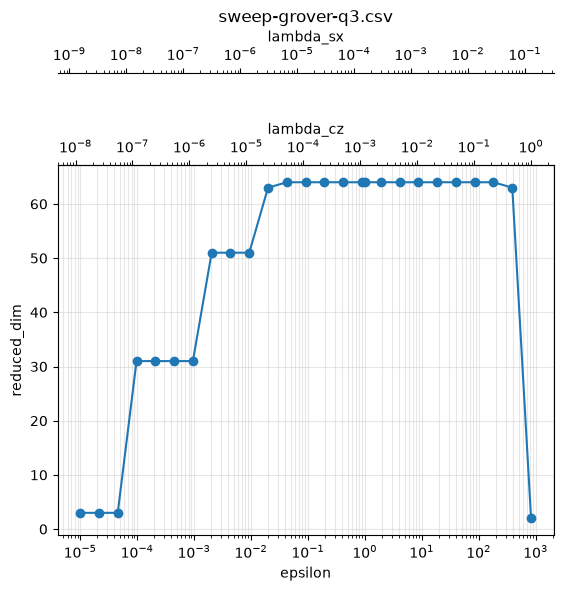

In [2]:
plot_sweep("sweep-grover-q3.csv", "reduced_dim");

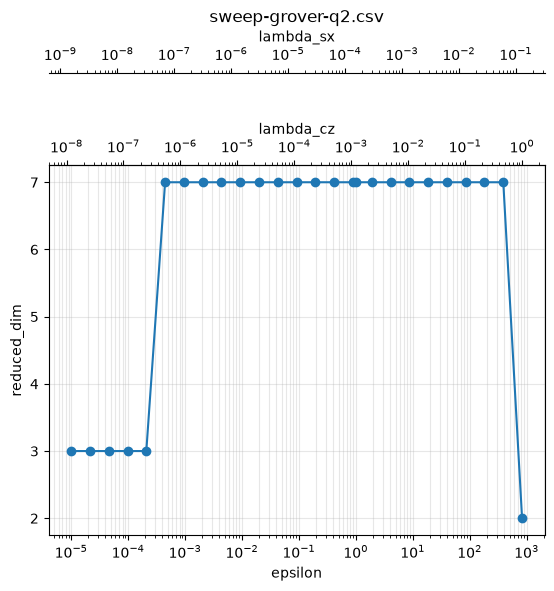

In [3]:
plot_sweep("sweep-grover-q2.csv", "reduced_dim");

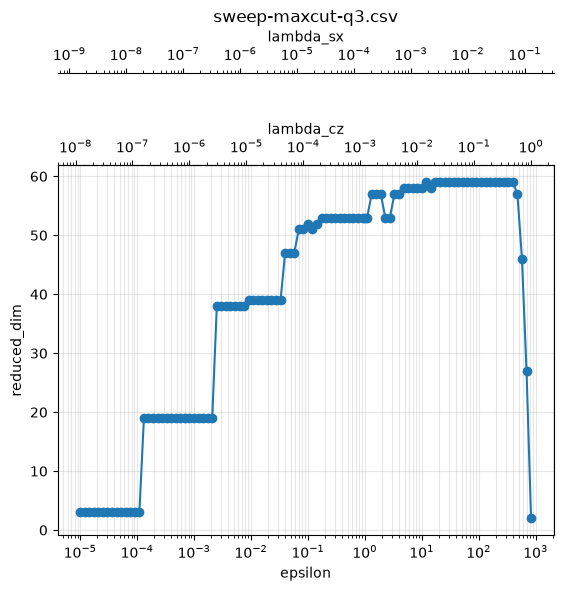

In [7]:
plot_sweep("sweep-maxcut-q3.csv", "reduced_dim");

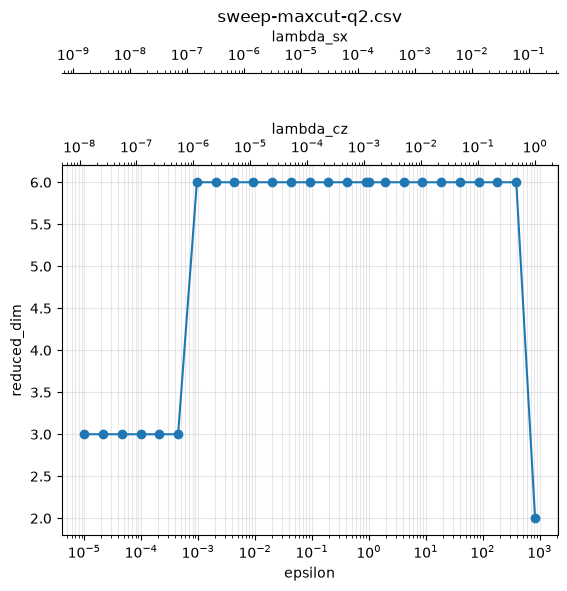

In [6]:
plot_sweep("sweep-maxcut-q2.csv", "reduced_dim");